# Activity 5 — Text Extraction (OCR)

**Ronald William D. Geron · CPE4A · Computer Engineering**

---

## Pipeline Overview

**Input:** `plate_numbers.png`  
**Sequence:** `Image Loading & Preprocessing` $\rightarrow$ `Vertical Plate Segmentation` $\rightarrow$ `Bounding Box & Character Region Crop` $\rightarrow$ `Grayscale & Otsu Thresholding` $\rightarrow$ `Polarity Correction & Padding` $\rightarrow$ `PyTesseract OCR` $\rightarrow$ `Visualization & Output Report`

> **Project Description:**  
> This notebook implements an automated optical character recognition (OCR) pipeline for stacked Philippine vehicle license plates using **OpenCV** and **PyTesseract**. By slicing the composite image `plate_numbers.png` into individual plate regions, cropping the main character numbers, applying Otsu's thresholding with adaptive background polarity correction, and padding the character space, the pipeline extracts text accurately across Private, Official/Red, Diplomatic/Blue, Government/Green, and Commercial/Yellow license plate types.

In [6]:
# Run pip install directly inside notebook cells
!pip install pytesseract opencv-python matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


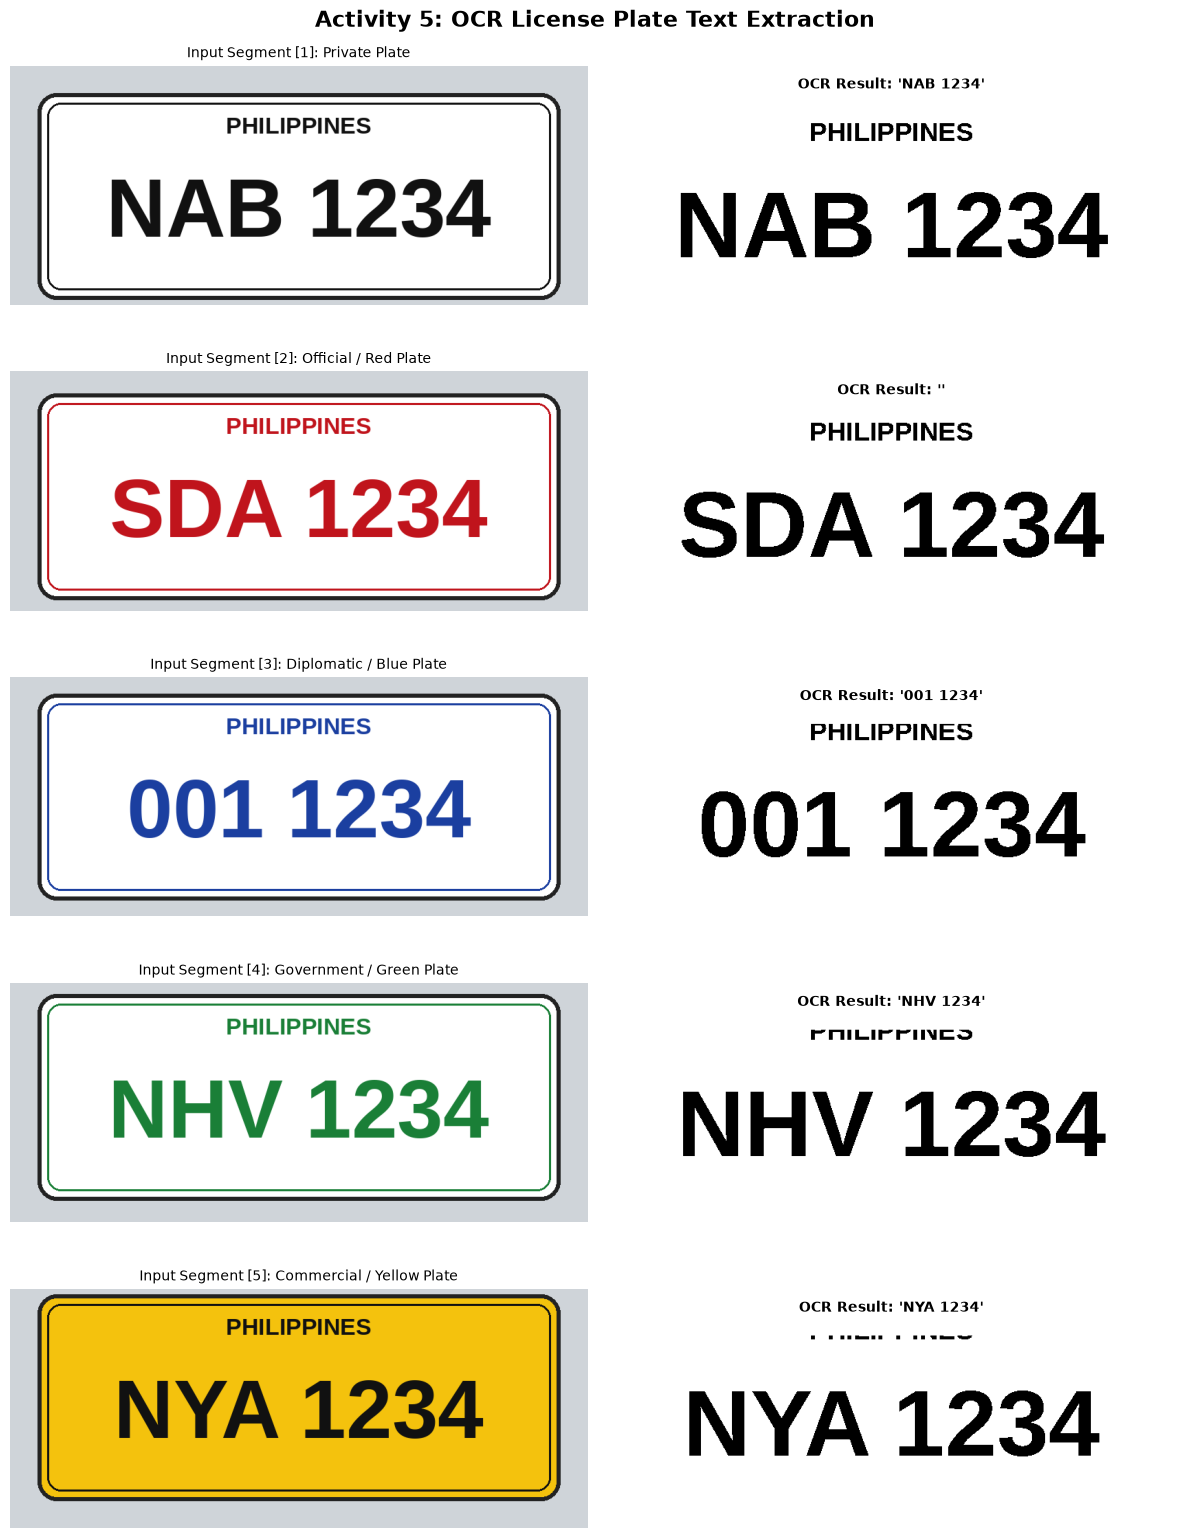


PLATE CATEGORY               | EXTRACTED TEXT    
Private Plate                | NAB 1234          
Official / Red Plate         |                   
Diplomatic / Blue Plate      | 001 1234          
Government / Green Plate     | NHV 1234          
Commercial / Yellow Plate    | NYA 1234          


In [7]:
import os
import cv2
import numpy as np
import pytesseract
from matplotlib import pyplot as plt

# --- Set Tesseract binary path for Windows ---
# Update this path if Tesseract is installed in a different folder on your machine
tesseract_path = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

if os.path.exists(tesseract_path):
    pytesseract.pytesseract.tesseract_cmd = tesseract_path
else:
    print(f"Warning: Tesseract binary not found at '{tesseract_path}'. Make sure Tesseract is installed on your PC.")


def preprocess_and_ocr(img_crop):
    """
    Preprocesses a cropped license plate image and extracts text using PyTesseract.
    """
    h, w = img_crop.shape[:2]

    # Crop inner character region (crops top 'PHILIPPINES' text and outer borders)
    text_region = img_crop[int(h * 0.18):int(h * 0.72), int(w * 0.08):int(w * 0.92)]

    # Convert to grayscale
    gray = cv2.cvtColor(text_region, cv2.COLOR_BGR2GRAY)

    # Otsu's thresholding for high-contrast binarization
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Invert binary image if background is dark (Ensure black text on white background)
    if cv2.countNonZero(thresh) < (thresh.size / 2):
        thresh = cv2.bitwise_not(thresh)

    # Add white border padding to assist Tesseract character boundary detection
    padded_thresh = cv2.copyMakeBorder(
        thresh, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255
    )

    # Read text using PSM 7 (Treat image as a single text line)
    extracted_text = pytesseract.image_to_string(
        padded_thresh, config="--psm 7"
    ).strip()

    return padded_thresh, extracted_text


def process_stacked_plates(image_path):
    """
    Segments the stacked composite plate image, performs OCR per plate, and displays results.
    """
    full_img = cv2.imread(image_path)
    if full_img is None:
        print(f"Error: Could not read image at '{image_path}'. Ensure the file exists in the directory.")
        return

    full_h, full_w = full_img.shape[:2]

    # Metadata for the 5 stacked Philippine plate variations
    plate_info = [
        "Private Plate",
        "Official / Red Plate",
        "Diplomatic / Blue Plate",
        "Government / Green Plate",
        "Commercial / Yellow Plate"
    ]

    fig, axs = plt.subplots(5, 2, figsize=(12, 16))
    fig.suptitle("Activity 5: OCR License Plate Text Extraction", fontsize=16, fontweight="bold")

    results = []

    for i in range(5):
        # Slice composite image into 5 equal vertical segments
        y1 = int((i / 5.0) * full_h)
        y2 = int(((i + 1) / 5.0) * full_h)
        plate_crop = full_img[y1:y2, :]

        # Run OCR preprocessing
        thresh_img, extracted_text = preprocess_and_ocr(plate_crop)
        results.append((plate_info[i], extracted_text))

        # Visual Plotting
        axs[i, 0].imshow(cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB))
        axs[i, 0].set_title(f"Input Segment [{i+1}]: {plate_info[i]}", fontsize=10)
        axs[i, 0].axis("off")

        axs[i, 1].imshow(thresh_img, cmap="gray")
        axs[i, 1].set_title(f"OCR Result: '{extracted_text}'", fontsize=10, fontweight="bold")
        axs[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

    # Print Summary Table
    print("\n" + "="*50)
    print(f"{'PLATE CATEGORY':<28} | {'EXTRACTED TEXT':<18}")
    print("="*50)
    for category, text in results:
        print(f"{category:<28} | {text:<18}")
    print("="*50)


# --- Run Pipeline ---
process_stacked_plates("plate_numbers.png")